<a href="https://colab.research.google.com/github/grsart/BiomolComp/blob/main/P06/MSA3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Alinhamento Múltiplo com o Clustal Omega

O [Clustal Omega](https://www.ebi.ac.uk/jdispatcher/msa/clustalo) é o sucessor do ClustalW. Ele **também é um método progressivo**: calcula uma árvore-guia e, seguindo essa árvore, vai adicionando as sequências ao alinhamento. A diferença está na forma como cada uma dessas etapas é feita:

1. **Árvore-guia mais rápida.** O ClustalW alinha todos os pares de sequências antes de construir a árvore-guia, o que fica muito lento quando há milhares de sequências. O Clustal Omega usa o método **mBed**, que compara cada sequência apenas com um pequeno conjunto de sequências de referência.
2. **Alinhamento de perfis com modelos ocultos de Markov (HMM).** Cada grupo de sequências já alinhadas é representado por um HMM de perfil, e os grupos são alinhados entre si comparando um HMM com o outro (programa HHalign). Isso tende a produzir alinhamentos mais precisos.

Com isso, o Clustal Omega obtém alinhamentos mais rápidos e, em geral, igualmente precisos ou mais precisos que os do ClustalW.

Nesta atividade usaremos o Clustal Omega *online* para alinhar as mesmas sequências **completas** que alinhamos no início da atividade anterior (arquivo `seqs2.fasta`), ou seja, sem recortar os domínios.

## 1. Clustal Omega Online

1. Abra o [Clustal Omega](https://www.ebi.ac.uk/jdispatcher/msa/clustalo) em uma nova aba do navegador.
2. Abra o arquivo [seqs2.fasta](https://raw.githubusercontent.com/grsart/BiomolComp/main/Pratica5/seqs2.fasta) em outra aba, selecione todo o conteúdo (Ctrl+A) e copie (Ctrl+C). As sequências estão em formato FASTA.
3. No formulário do Clustal Omega, verifique se o tipo de sequência está como **Protein** e cole as sequências no campo de entrada de sequências.
4. Clique em "*Submit*" e aguarde o resultado.

### Análise do Alinhamento

Na página de resultados, ative a coloração dos resíduos (botão "**Show Colors**", se disponível) e procure a visualização da árvore-guia (*guide tree*).

Lembre-se de que, na atividade anterior, um bom alinhamento deveria mostrar os motivos conservados **YRP**, **FADD** e **(Y/I)LG** em todas as sequências.

### Questão 10

**A) Você consegue identificar as regiões tipicamente conservadas (YRP, FADD e (Y/I)LG) que você viu na atividade anterior? Compare com o alinhamento das sequências completas feito pelo ClustalW.**

**B) Como fica a árvore-guia (*guide tree*) neste novo alinhamento?**

**C) Qual a diferença da árvore-guia para a árvore filogenética?**

## 2. Clustal Omega no Colab (opcional)

O Clustal Omega também pode ser executado aqui no Colab. Isso é útil caso o servidor do EBI esteja fora do ar, e também permite comparar diretamente, com as mesmas ferramentas da atividade anterior, os alinhamentos produzidos pelo ClustalW e pelo Clustal Omega.

A célula abaixo prepara o ambiente (Biopython, ClustalW e as funções auxiliares da atividade anterior) e instala o Clustal Omega.

In [1]:
#@title Preparando o Ambiente para a Execução

# Instalando o Biopython e importando as bibliotecas necessárias...

%pip install -q biopython
import os
import re
import subprocess
from collections import Counter
from Bio import SeqIO, AlignIO, Phylo

# Baixando o ClustalW2 (apenas se ainda não estiver disponível)...

if not os.path.isfile("clustalw2"):
    !wget -q -nc https://ftp.ebi.ac.uk/pub/software/clustalw2/2.1/clustalw-2.1-linux-x86_64-libcppstatic.tar.gz
    !tar -xzf clustalw-2.1-linux-x86_64-libcppstatic.tar.gz
    !mv clustalw-2.1-linux-x86_64-libcppstatic/clustalw2 .

assert os.path.isfile("clustalw2"), "Executável do ClustalW não encontrado"

# Funções auxiliares...

def rodar_clustalw(arquivo_fasta, saida_aln=None, **opcoes):
    """Executa o ClustalW e devolve (arquivo .aln, arquivo .dnd, saída do programa).

    Opções extras viram parâmetros do programa, por exemplo gapopen=2 -> -GAPOPEN=2.
    """
    base = os.path.splitext(arquivo_fasta)[0]
    saida_aln = saida_aln or base + ".aln"
    comando = ["./clustalw2", f"-INFILE={arquivo_fasta}", f"-OUTFILE={saida_aln}"]
    comando += [f"-{nome.upper()}={valor}" for nome, valor in opcoes.items()]
    resultado = subprocess.run(comando, capture_output=True, text=True, check=True)
    return saida_aln, base + ".dnd", resultado.stdout


def scores_par_a_par(saida):
    """Extrai da saída do ClustalW o score de cada alinhamento par a par."""
    padrao = r"Sequences \((\d+):(\d+)\) Aligned\. Score:\s*([\d.]+)"
    return {(int(i), int(j)): float(s) for i, j, s in re.findall(padrao, saida)}


def mostrar_scores(arquivo_fasta, saida):
    """Mostra os scores par a par com os nomes das sequências."""
    nomes = [rec.id for rec in SeqIO.parse(arquivo_fasta, "fasta")]
    scores = scores_par_a_par(saida)
    if not scores:
        print(saida)
        return
    print("Score  Par de sequências")
    for (i, j), score in scores.items():
        print(f"{score:5.0f}  {nomes[i - 1]}  x  {nomes[j - 1]}")


def ocorrencias_do_motivo(alinhamento, motivo):
    """Localiza o motivo (expressão regular) em cada sequência, ignorando os gaps,
    e devolve as colunas do alinhamento onde cada ocorrência começa e termina."""
    ocorrencias = {}
    for rec in alinhamento:
        alinhada = str(rec.seq)
        colunas = [k + 1 for k, c in enumerate(alinhada) if c != "-"]  # coluna de cada resíduo
        sem_gaps = alinhada.replace("-", "")
        ocorrencias[rec.id] = [(m.group(), colunas[m.start()], colunas[m.end() - 1])
                               for m in re.finditer(motivo, sem_gaps)]
    return ocorrencias


def mostrar_motivo(alinhamento, motivo):
    """Mostra em que colunas do alinhamento o motivo aparece em cada sequência."""
    ocorrencias = ocorrencias_do_motivo(alinhamento, motivo)
    print(f"Motivo {motivo}")
    for nome, lista in ocorrencias.items():
        if lista:
            descricao = ", ".join(f"{m} (colunas {ini}-{fim})" + (" interrompido por gaps" if fim - ini + 1 > len(m) else "")
                                  for m, ini, fim in lista)
        else:
            descricao = "não encontrado"
        print(f"  {nome:40s} {descricao}")
    contagem = Counter(ini for lista in ocorrencias.values() for _, ini, _ in lista)
    if contagem:
        coluna, n = contagem.most_common(1)[0]
        print(f"  => Começando na coluna {coluna}, o motivo está alinhado em {n} de {len(alinhamento)} sequências.")
    print()


print("Ambiente pronto!")

# Instalando o Clustal Omega...

!apt-get -qq install -y clustalo > /dev/null
!clustalo --version

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 29.7 MB/s eta 0:00:00
Ambiente pronto!
1.2.4


In [2]:
seq_file = "seqs2.fasta"
!wget -q -nc https://raw.githubusercontent.com/grsart/BiomolComp/main/Pratica5/seqs2.fasta

# Alinhamento com o Clustal Omega
!clustalo -i {seq_file} -o seqs2_clustalo.aln --outfmt=clustal --guidetree-out=seqs2_clustalo.dnd --force
!cat seqs2_clustalo.aln

CLUSTAL O(1.2.4) multiple sequence alignment


tr|Q9ZQM0|Q9ZQM0_ARATH      ------------------------------------------------------------
tr|O93520|O93520_ORYLA      -MYDRN-----VKLLTLNINGLHNPVKRWKTLSKLKQDKAEIVFLQETHLPEAE-HLKLN
tr|Q93137|Q93137_BOMMO      MAYISRIKPLSVTIGFFNAYGLANQRD--QVSDFLRDHQIDIFLVQETLLKPARRDPKIA
tr|Q24335|Q24335_DROME      --------MATLRIATWNANGVSQRKL--ELAQFLHEKHIDVMLLSETHLTSKY-NFQIR
                                                                                        

tr|Q9ZQM0|Q9ZQM0_ARATH      ------------------------------------------------------------
tr|O93520|O93520_ORYLA      KMGFKHVFYSSHSSGRRR-GVATLIAGAVNYQHVSEYKDKEGRY-IMITGKINSILITLL
tr|Q93137|Q93137_BOMMO      N---YNMVRNDRL-SARGGGTVIYYRRALHCVPLDPPALANIEASVCRISLTGHAPIVIA
tr|Q24335|Q24335_DROME      D---YHFYGTNHPDGKAHGGTAILIRNRMKHHFYKEFAENHLQATSINIQLDDNTLLTLA
                                                                                        

tr|Q9ZQM0|Q9ZQM0_ARATH      ----------------------------MAECD

Agora vamos procurar os motivos conservados no alinhamento do Clustal Omega e no alinhamento das mesmas sequências feito pelo ClustalW (com os pesos de *gap* da atividade anterior).

In [3]:
aln_clustalw, _, _ = rodar_clustalw(seq_file, "seqs2_clustalw.aln", gapopen=2, gapext=0.1)

alinhamentos = {
    "Clustal Omega": AlignIO.read("seqs2_clustalo.aln", "clustal"),
    "ClustalW": AlignIO.read(aln_clustalw, "clustal"),
}
for programa, align in alinhamentos.items():
    print(f"===== {programa} =====")
    for motivo in ["YRP", "FADD", "[YI]LG"]:
        mostrar_motivo(align, motivo)

===== Clustal Omega =====
Motivo YRP
  tr|Q9ZQM0|Q9ZQM0_ARATH                   YRP (colunas 577-579)
  tr|O93520|O93520_ORYLA                   YRP (colunas 577-579)
  tr|Q93137|Q93137_BOMMO                   YRP (colunas 577-579)
  tr|Q24335|Q24335_DROME                   YRP (colunas 577-579)
  => Começando na coluna 577, o motivo está alinhado em 4 de 4 sequências.

Motivo FADD
  tr|Q9ZQM0|Q9ZQM0_ARATH                   FADD (colunas 756-759)
  tr|O93520|O93520_ORYLA                   FADD (colunas 756-759)
  tr|Q93137|Q93137_BOMMO                   FADD (colunas 756-759)
  tr|Q24335|Q24335_DROME                   FADD (colunas 756-759)
  => Começando na coluna 756, o motivo está alinhado em 4 de 4 sequências.

Motivo [YI]LG
  tr|Q9ZQM0|Q9ZQM0_ARATH                   ILG (colunas 829-834) interrompido por gaps, YLG (colunas 844-846)
  tr|O93520|O93520_ORYLA                   YLG (colunas 844-846), YLG (colunas 1256-1258)
  tr|Q93137|Q93137_BOMMO                   ILG (colunas 149-1

Por fim, a árvore-guia calculada pelo Clustal Omega:

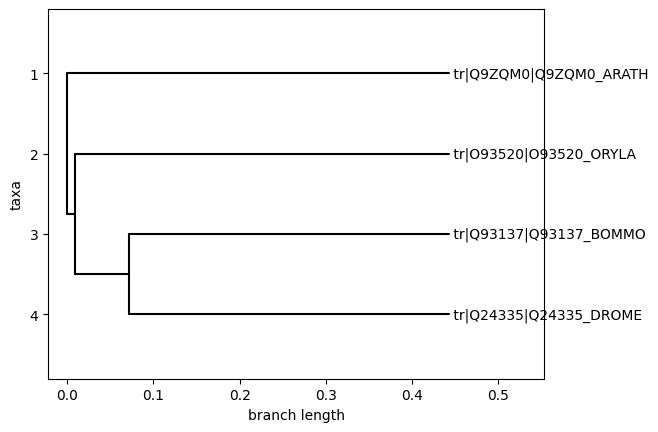

In [4]:
Phylo.draw(Phylo.read("seqs2_clustalo.dnd", "newick"))